In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

# Find the data folder whether the notebook is run from notebooks/ or 01_Dataset_Analysis/
base = ".." if os.path.exists(os.path.join("..", "data")) else "."
raw = pd.read_csv(os.path.join(base, "data", "synthetic", "synthetic_pricing.csv"))
clean = pd.read_csv(os.path.join(base, "data", "processed", "synthetic_pricing_clean.csv"))
truth = pd.read_csv(os.path.join(base, "data", "synthetic", "synthetic_ground_truth.csv"))
print("Raw:", raw.shape, "| Clean:", clean.shape, "| Ground truth:", truth.shape)

Raw: (20000, 11) | Clean: (20000, 14) | Ground truth: (20000, 6)


## 1. First look

In [2]:
clean.head()

,customer_id,age,region,monthly_income,loyalty_member,past_purchases,days_since_last_purchase,avg_basket_value,discount,purchased,spend,age_group,income_tier,recency_group
0,CUST_00001,22,West,33900,0,3,57,102,10,1,81,young,medium,lapsed
1,CUST_00002,55,West,115000,0,2,73,185,10,0,0,older,high,lapsed
2,CUST_00003,49,South,27000,1,5,13,182,10,1,149,adult,medium,recent
3,CUST_00004,39,North,38400,0,4,78,71,10,1,47,adult,medium,lapsed
4,CUST_00005,38,South,61400,0,2,77,69,0,0,0,adult,high,lapsed


In [3]:
clean.dtypes

customer_id                   str
age                         int64
region                        str
monthly_income              int64
loyalty_member              int64
past_purchases              int64
days_since_last_purchase    int64
avg_basket_value            int64
discount                    int64
purchased                   int64
spend                       int64
age_group                     str
income_tier                   str
recency_group                 str
dtype: object

## 2. Data quality checks

In [4]:
checks = pd.DataFrame({
    "Check": ["Rows", "Columns", "Missing values", "Duplicate rows", "Duplicate customer_id"],
    "Result": [len(raw), raw.shape[1], int(raw.isna().sum().sum()),
               int(raw.duplicated().sum()), int(raw["customer_id"].duplicated().sum())],
})
checks

,Check,Result
0,Rows,20000
1,Columns,11
2,Missing values,0
3,Duplicate rows,0
4,Duplicate customer_id,0


In [5]:
valid = pd.DataFrame({
    "Rule": ["discount in {0,10,20}", "purchased in {0,1}", "age 18-100", "income > 0",
             "basket value > 0", "spend = 0 when not purchased"],
    "Rows failing": [
        int((~raw["discount"].isin([0, 10, 20])).sum()),
        int((~raw["purchased"].isin([0, 1])).sum()),
        int((~raw["age"].between(18, 100)).sum()),
        int((raw["monthly_income"] <= 0).sum()),
        int((raw["avg_basket_value"] <= 0).sum()),
        int(((raw["purchased"] == 0) & (raw["spend"] > 0)).sum()),
    ],
})
valid

,Rule,Rows failing
0,"discount in {0,10,20}",0
1,"purchased in {0,1}",0
2,age 18-100,0
3,income > 0,0
4,basket value > 0,0
5,spend = 0 when not purchased,0


In [6]:
raw.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
age,20000.0,41.3,13.8,18.0,29.0,41.0,53.0,65.0
monthly_income,20000.0,37551.3,20144.0,5000.0,23600.0,33100.0,46400.0,377000.0
loyalty_member,20000.0,0.4,0.5,0.0,0.0,0.0,1.0,1.0
past_purchases,20000.0,3.1,2.3,0.0,1.0,3.0,4.0,14.0
days_since_last_purchase,20000.0,31.5,31.9,1.0,9.0,22.0,43.0,348.0
avg_basket_value,20000.0,205.8,110.8,16.0,129.0,181.0,255.0,1795.0
discount,20000.0,9.7,8.0,0.0,0.0,10.0,20.0,20.0
purchased,20000.0,0.5,0.5,0.0,0.0,1.0,1.0,1.0
spend,20000.0,108.4,134.6,0.0,0.0,73.5,183.0,1819.0


## 3. Variable roles
| Role | Columns |
|---|---|
| X (pre-treatment features) | age, region, monthly_income, loyalty_member, past_purchases, days_since_last_purchase, avg_basket_value (+ age_group, income_tier, recency_group) |
| T (treatment) | discount (0, 10, 20) |
| Y (outcome) | purchased (0/1) |
| Not features | spend (measured after the discount), customer_id, ground-truth file |

## 4. Customer features

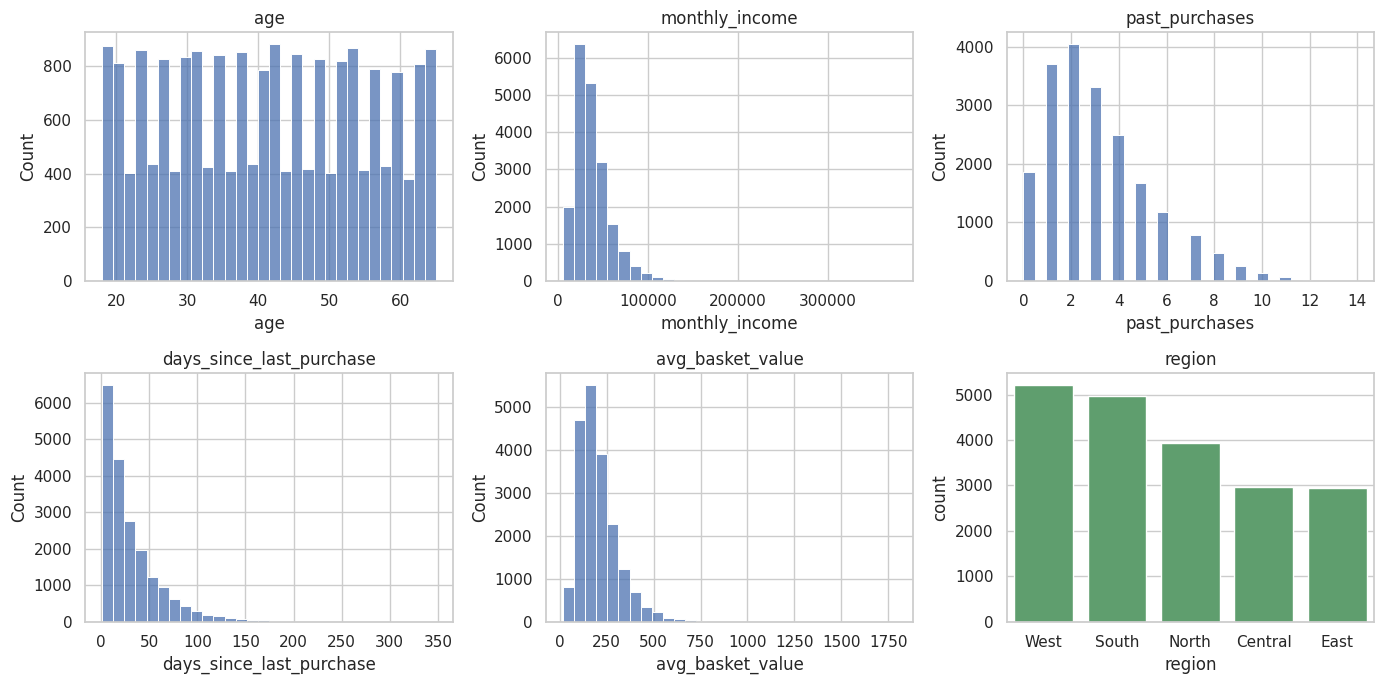

In [7]:
num_cols = ["age", "monthly_income", "past_purchases", "days_since_last_purchase", "avg_basket_value"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(clean[col], bins=30, ax=ax, color="#4C72B0")
    ax.set_title(col)
sns.countplot(data=clean, x="region", ax=axes.flat[5], color="#55A868")
axes.flat[5].set_title("region")
plt.tight_layout()
plt.show()

In [8]:
print("Loyalty members: {:.1%}".format(clean["loyalty_member"].mean()))
for g in ["age_group", "income_tier", "recency_group"]:
    print(g, clean[g].value_counts().to_dict())

Loyalty members: 35.1%
age_group {'adult': 8396, 'older': 6548, 'young': 5056}
income_tier {'medium': 12776, 'high': 4075, 'low': 3149}
recency_group {'recent': 7813, 'moderate': 7600, 'lapsed': 4587}


## 5. How were discounts given? (the treatment)

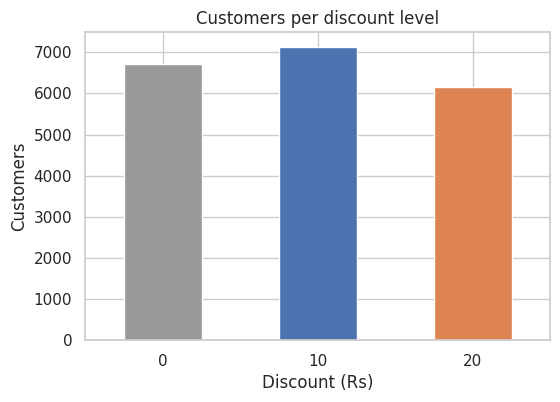

discount
0     0.335
10    0.356
20    0.308
Name: count, dtype: float64

In [9]:
counts = clean["discount"].value_counts().sort_index()
ax = counts.plot(kind="bar", color=["#999999", "#4C72B0", "#DD8452"], figsize=(6, 4))
ax.set_xlabel("Discount (Rs)"); ax.set_ylabel("Customers"); ax.set_title("Customers per discount level")
plt.xticks(rotation=0); plt.show()
(counts / counts.sum()).round(3)

Discounts were **not** handed out at random. The table below compares the average customer in each discount group. If discounts were random, the rows would look the same.

In [10]:
clean.groupby("discount")[["past_purchases", "days_since_last_purchase",
                           "loyalty_member", "monthly_income", "avg_basket_value", "age"]].mean().round(2)

,past_purchases,days_since_last_purchase,loyalty_member,monthly_income,avg_basket_value,age
discount,,,,,,
0,2.52,36.28,0.31,37730.93,206.25,41.16
10,3.07,30.15,0.34,37477.77,204.36,41.42
20,3.62,27.90,0.41,37441.06,207.01,41.43


**Reading this:** customers who got bigger discounts already had more past purchases and more recent activity. Those customers are also more likely to buy with no discount at all. This is **confounding**.

## 6. Does a discount increase purchases? (naive view)

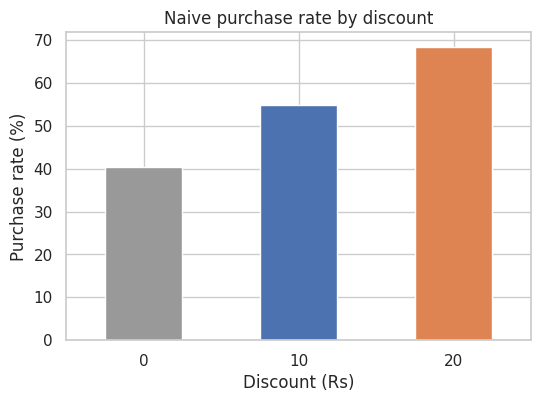

Naive effect of Rs 10 vs none: +14.6 points
Naive effect of Rs 20 vs none: +28.1 points


In [11]:
naive = clean.groupby("discount")["purchased"].mean()
ax = naive.mul(100).plot(kind="bar", color=["#999999", "#4C72B0", "#DD8452"], figsize=(6, 4))
ax.set_xlabel("Discount (Rs)"); ax.set_ylabel("Purchase rate (%)"); ax.set_title("Naive purchase rate by discount")
plt.xticks(rotation=0); plt.show()
print("Naive effect of Rs 10 vs none: {:+.1f} points".format((naive[10] - naive[0]) * 100))
print("Naive effect of Rs 20 vs none: {:+.1f} points".format((naive[20] - naive[0]) * 100))

## 7. Naive estimate vs the true effect
The ground-truth file is the **answer key**, used here only to judge the data. It must never be used to train a model.

,Naive (points),True (points),Naive is too high by
Rs 10,14.6,9.9,4.7
Rs 20,28.1,20.0,8.0


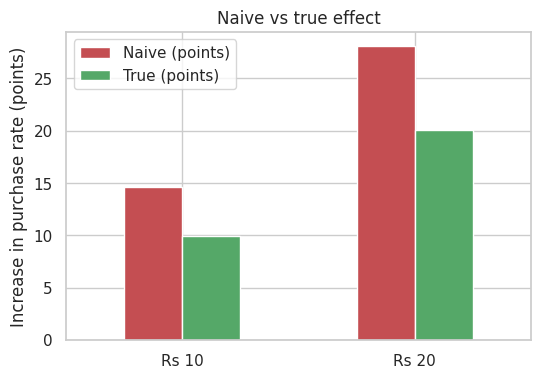

In [12]:
true_avg = truth[["true_uplift_10", "true_uplift_20"]].mean() * 100
cmp = pd.DataFrame({
    "Naive (points)": [(naive[10] - naive[0]) * 100, (naive[20] - naive[0]) * 100],
    "True (points)": [true_avg["true_uplift_10"], true_avg["true_uplift_20"]],
}, index=["Rs 10", "Rs 20"])
cmp["Naive is too high by"] = cmp["Naive (points)"] - cmp["True (points)"]
display(cmp.round(1))
cmp[["Naive (points)", "True (points)"]].plot(kind="bar", figsize=(6, 4), color=["#C44E52", "#55A868"])
plt.ylabel("Increase in purchase rate (points)"); plt.title("Naive vs true effect"); plt.xticks(rotation=0); plt.show()

**Takeaway:** the naive comparison overstates the effect of the discount, because customers who got discounts were more likely to buy anyway. A good causal model (DML) should land close to the **True** bars, not the naive ones.

## 8. Overlap check
For causal modelling, every type of customer should have some chance of getting each discount. If a group never receives a certain discount, the model cannot learn that group's effect.

In [13]:
for g in ["age_group", "income_tier", "recency_group"]:
    print(g)
    display((pd.crosstab(clean[g], clean["discount"], normalize="index") * 100).round(1))

age_group


discount,0,10,20
age_group,,,
adult,34.0,36.1,29.9
older,32.7,35.5,31.8
young,33.7,35.0,31.2


income_tier


discount,0,10,20
income_tier,,,
high,33.7,35.8,30.6
low,33.0,35.5,31.5
medium,33.6,35.6,30.8


recency_group


discount,0,10,20
recency_group,,,
lapsed,40.7,34.1,25.2
moderate,33.0,35.3,31.7
recent,29.9,36.9,33.2


In [14]:
share = pd.crosstab(pd.cut(clean["past_purchases"], [-1, 1, 3, 5, 100],
                           labels=["0-1", "2-3", "4-5", "6+"]), clean["discount"], normalize="index") * 100
share.round(1)

discount,0,10,20
past_purchases,,,
0-1,43.1,34.3,22.7
2-3,34.2,36.7,29.0
4-5,29.2,35.8,35.1
6+,19.8,35.4,44.8


Every group receives all three discount levels, so overlap is adequate. The shares do shift with past purchases and recency, which is the confounding DML must adjust for.

## 9. Do different customers respond differently?
Using the answer key to see how the true effect of a Rs 10 discount varies by customer type. This is what the model should try to learn.

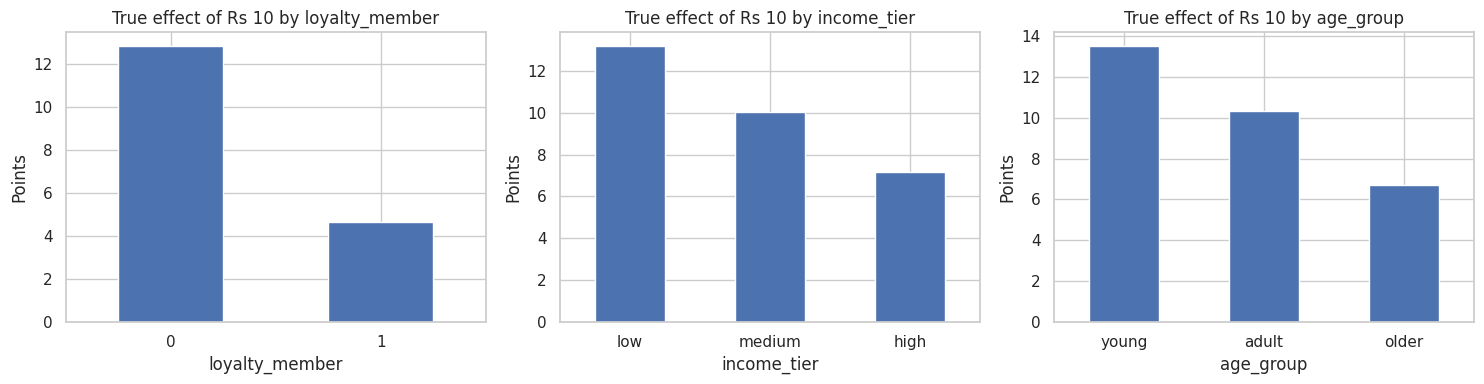

In [15]:
eval_df = clean.merge(truth, on="customer_id")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, g in zip(axes, ["loyalty_member", "income_tier", "age_group"]):
    order = ["low", "medium", "high"] if g == "income_tier" else (["young", "adult", "older"] if g == "age_group" else None)
    (eval_df.groupby(g)["true_uplift_10"].mean() * 100).reindex(order if order else [0, 1]).plot(
        kind="bar", ax=ax, color="#4C72B0")
    ax.set_title("True effect of Rs 10 by " + g); ax.set_ylabel("Points"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

In [16]:
print("Spread of true Rs 10 effect across customers (points): min {:.1f}, median {:.1f}, max {:.1f}".format(
    eval_df["true_uplift_10"].min() * 100, eval_df["true_uplift_10"].median() * 100, eval_df["true_uplift_10"].max() * 100))

Spread of true Rs 10 effect across customers (points): min 0.1, median 9.8, max 28.0


## 10. Summary of findings
| Finding | Detail |
|---|---|
| Data quality | 20,000 rows, no missing values, duplicates or invalid values |
| Treatment assignment | Not random. Customers with more past purchases and recent activity received discounts more often |
| Naive effect | Overstates the discount effect (about 15 points for Rs 10 vs a true 10) |
| Overlap | All customer groups receive all discount levels |
| Heterogeneity | The true effect differs by customer type, so one average effect is not enough |
| Leakage rules | Do not use discount, purchased, spend, customer_id or the ground-truth file as features |

**Next steps:** hand over `data/processed/synthetic_pricing_clean.csv` and `docs/dataset_dictionary.md` to Member 2 for the DML baseline.